# Generador de Gráficos 1.4 a 1.7 (Estandarizado Villa Gaucho)

Este cuaderno es una versión estandarizada de `generador_graficos 1_4 - 1_7.ipynb`, aplicando las especificaciones de diseño y formato del Informe de Villa Gaucho:
- **Tipografía y tamaño de letra 14**: configurado globalmente para títulos, etiquetas de ejes, valores y señalizaciones.
- **Gráficos de Torta (Cualitativas)**:
  - Sin líneas blancas divisorias (`edgecolor='none'`).
  - Frecuencia absoluta en el interior de cada cuña (tamaño 14).
  - Línea directa que conecta con donde comienza el texto (sin subrayar).
  - Nombre de la categoría arriba de la línea y porcentaje abajo (`X,X%`).
  - Orden estricto de mayor a menor porcentaje con la paleta: 1. Azul (`#4285F4`), 2. Naranja (`#FB8C00`), 3. Verde (`#34A853`), 4. Amarillo (`#FBBC05`), 5. Violeta (`#8E24AA`), 6. Beige (`#D7CCC8`).
  - Preguntas binarias (ej. 1.7 uso de sal Sí / No): **Positivo = Azul (`#4285F4`)**, **Negativo = Naranja (`#FB8C00`)**.
- **Pregunta 1.5 (Equipamiento para cocinar)**:
  - Al poseer **más de 5 categorías** (7 categorías), se representa mediante un **gráfico de barras horizontales** que utiliza exactamente la misma paleta y orden de colores que el gráfico de torta, aplicando además la regla de frecuencias < 2% afuera de la barra.


In [1]:
# ==============================================================================
# 1. IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN GLOBAL
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configuración global de tamaño de letra 14
plt.rcParams['font.size'] = 14
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.labelsize'] = 14
plt.rcParams['legend.fontsize'] = 14
plt.rcParams['figure.titlesize'] = 14

# Paleta para tortas (de mayor a menor porcentaje)
PALETA_TORTA = [
    '#4285F4',  # 1. Azul
    '#FB8C00',  # 2. Naranja
    '#34A853',  # 3. Verde
    '#FBBC05',  # 4. Amarillo
    '#8E24AA',  # 5. Violeta
    '#D7CCC8'   # 6. Beige
]

# Color estándar para gráficos de barras de un solo color
COLOR_BARRAS_UNICO = '#1b7882'

# Colores para preguntas binarias (Positivo / Negativo)
COLOR_POSITIVO = '#4285F4'  # Azul
COLOR_NEGATIVO = '#FB8C00'  # Naranja


In [2]:
# ==============================================================================
# 2. FUNCIONES DE GRAFICACIÓN ESTANDARIZADAS
# ==============================================================================
def graficar_torta(categorias, valores, titulo="", es_binario=False, orden_positivo_primero=True, figsize=(11, 7), distancia_etiquetas_y=0.45):
    """
    Genera un gráfico de torta con el formato del Informe Villa Gaucho:
    - Sin bordes blancos entre porciones.
    - Frecuencia absoluta adentro de cada cuña (tamaño 14).
    - Línea conector directa al inicio del texto (sin subrayar).
    - Nombre de la categoría arriba de la línea, porcentaje abajo.
    - Si es binario (Sí/No): Positivo = Azul, Negativo = Naranja.
    - Si es multicategoría: orden de mayor a menor con paleta institucional.
    - Distribución balanceada verticalmente en el recuadro.
    """
    df_temp = pd.DataFrame({'categoria': [str(c) for c in categorias], 'fi': list(valores)})

    if es_binario:
        def es_pos(val):
            val_clean = str(val).strip().lower()
            return val_clean in ['si', 'sí', 'positivo', 'true', 'afirma', 'posee', 'tiene', 'concurre']

        df_temp['es_pos'] = df_temp['categoria'].apply(es_pos)
        if orden_positivo_primero:
            df_temp = df_temp.sort_values(by='es_pos', ascending=False).reset_index(drop=True)
        colores = [COLOR_POSITIVO if p else COLOR_NEGATIVO for p in df_temp['es_pos']]
    else:
        df_temp = df_temp.sort_values(by='fi', ascending=False).reset_index(drop=True)
        colores = [PALETA_TORTA[i % len(PALETA_TORTA)] for i in range(len(df_temp))]

    cats = df_temp['categoria'].tolist()
    vals = df_temp['fi'].values
    total = sum(vals)
    pcts = (vals / total) * 100 if total > 0 else np.zeros_like(vals)

    fig, ax = plt.subplots(figsize=figsize, subplot_kw=dict(aspect="equal"))

    wedges, texts, autotexts = ax.pie(
        vals,
        autopct='%1.0f',
        pctdistance=0.68,
        colors=colores,
        startangle=90,
        counterclock=False,
        wedgeprops=dict(width=1, edgecolor='none')
    )

    for at, val in zip(autotexts, vals):
        at.set_text(str(int(val)))
        at.set_color('#202124')
        at.set_fontsize(14)
        at.set_fontweight('medium')

    wedge_items = []
    for i, p in enumerate(wedges):
        ang = (p.theta2 - p.theta1) / 2.0 + p.theta1
        rad = np.deg2rad(ang)
        x = np.cos(rad)
        y = np.sin(rad)
        lado = 1 if x >= 0 else -1
        wedge_items.append({
            'index': i,
            'ang': ang,
            'rad': rad,
            'x': x,
            'y': y,
            'lado': lado,
            'y_afuera': 1.15 * y
        })

    ax.set_xlim(-2.4, 2.4)
    ax.set_ylim(-1.6, 1.6)

    # Distribución balanceada vertical
    for lado in [1, -1]:
        group = [item for item in wedge_items if item['lado'] == lado]
        if not group:
            continue
        group.sort(key=lambda item: item['y'])
        k = len(group)
        if k == 1:
            group[0]['y_afuera'] = group[0]['y'] * 1.15
        else:
            span = (k - 1) * distancia_etiquetas_y
            avg_y = np.mean([item['y'] for item in group])
            start_y = avg_y - (span / 2.0)
            start_y = max(-1.30, min(1.30 - span, start_y))
            for idx_g, item in enumerate(group):
                item['y_afuera'] = start_y + idx_g * distancia_etiquetas_y

    for item in wedge_items:
        i = item['index']
        rad = item['rad']
        x_punto = 0.90 * np.cos(rad)
        y_punto = 0.90 * np.sin(rad)

        lado = item['lado']
        y_afuera = item['y_afuera']
        ha = 'left' if lado == 1 else 'right'
        pct_str = f"{pcts[i]:.1f}%".replace('.', ',')

        x_texto = 1.95 * lado

        # 1. Categoría ARRIBA
        ax.text(
            x_texto, y_afuera + 0.03,
            cats[i],
            horizontalalignment=ha,
            verticalalignment='bottom',
            fontsize=14,
            color='#202124',
            fontweight='medium'
        )

        # 2. Porcentaje ABAJO
        ax.text(
            x_texto, y_afuera - 0.03,
            pct_str,
            horizontalalignment=ha,
            verticalalignment='top',
            fontsize=14,
            color='#757575',
            fontweight='normal'
        )

        # 3. Línea que conecta directamente al inicio del texto (SIN SUBRAYAR)
        ax.plot([x_punto, x_texto], [y_punto, y_afuera], color='#9e9e9e', lw=1.2)
        ax.plot(x_punto, y_punto, marker='o', markersize=4, color='#9e9e9e')

    if titulo:
        ax.set_title(titulo, fontsize=14, pad=25, fontweight='bold', color='#202124')

    plt.subplots_adjust(left=0.08, right=0.92, top=0.88, bottom=0.10)
    plt.show()


def graficar_barras_horizontales(etiquetas, valores, titulo="", xlabel="Cantidad de respuestas", ylabel="", sufijo_etiqueta="", usar_colores_torta=False, ordenar_mayor_a_menor=False, figsize=(12, 6)):
    """
    Genera un gráfico de barras horizontales estandarizado:
    - Si porcentaje < 2%, frecuencia y porcentaje van afuera de la barra.
    - Si porcentaje >= 2%, frecuencia adentro de la barra (blanco, negrita) y porcentaje afuera.
    - Si usar_colores_torta=True, asigna los colores de la torta de mayor a menor porcentaje.
    """
    df_temp = pd.DataFrame({'etiqueta': [str(e) for e in etiquetas], 'fi': list(valores)})
    
    if ordenar_mayor_a_menor:
        df_temp = df_temp.sort_values(by='fi', ascending=False).reset_index(drop=True)
        df_temp = df_temp.iloc[::-1].reset_index(drop=True)

    valores = np.array(df_temp['fi'].values, dtype=float)
    etiquetas = df_temp['etiqueta'].tolist()
    total = np.sum(valores)
    porcentajes = (valores / total) * 100 if total > 0 else np.zeros_like(valores)
    n = len(etiquetas)

    fig, ax = plt.subplots(figsize=figsize)

    if usar_colores_torta:
        if ordenar_mayor_a_menor:
            ranks = n - 1 - np.arange(n)
            colores = [PALETA_TORTA[r % len(PALETA_TORTA)] for r in ranks]
        else:
            colores = [PALETA_TORTA[i % len(PALETA_TORTA)] for i in range(n)]
    else:
        colores = COLOR_BARRAS_UNICO

    barras = ax.barh(
        range(n),
        valores,
        color=colores,
        height=0.68,
        edgecolor='none'
    )

    ax.set_yticks(range(n))
    if sufijo_etiqueta:
        labels_y = [f"{lbl} {sufijo_etiqueta}" if int(lbl) != 1 else f"{lbl} {sufijo_etiqueta.rstrip('s')}" for lbl in etiquetas]
    else:
        labels_y = [str(lbl) for lbl in etiquetas]
    ax.set_yticklabels(labels_y, fontsize=14)

    max_val = max(valores) if len(valores) > 0 else 1
    offset_texto = max_val * 0.025

    for barra, cantidad, porcentaje in zip(barras, valores, porcentajes):
        x = barra.get_width()
        y = barra.get_y() + barra.get_height() / 2.0

        # REGLA DEL 2%:
        if porcentaje < 2.0:
            ax.text(
                x + offset_texto, y,
                f"{int(cantidad)} ({porcentaje:.1f}%)".replace('.', ','),
                ha='left', va='center',
                color='#202124', fontsize=14, fontweight='medium'
            )
        else:
            ax.text(
                x / 2.0, y, str(int(cantidad)),
                ha='center', va='center',
                color='white', fontweight='bold', fontsize=14
            )
            ax.text(
                x + offset_texto, y,
                f"{porcentaje:.1f}%".replace('.', ','),
                ha='left', va='center',
                color='#202124', fontsize=14
            )

    if titulo:
        ax.set_title(titulo, fontsize=14, pad=15, fontweight='bold')
    ax.set_xlabel(xlabel, fontsize=14, labelpad=10)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=14, labelpad=10)

    ax.set_xlim(0, max_val * 1.25)
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()


## 3. Carga y Estandarización de Datos


In [3]:
# Cargar el archivo CSV con los datos del proyecto
df = pd.read_csv('datos.csv')

# Subconjuntos de datos
df_1_4 = df[['1.4 ¿Qué usa para cocinar?']]
df_1_5 = df[['1.5 En el hogar, para cocinar tienen:']]
df_1_6 = df[['1.6 De las comidas de la última semana, ¿cuántas fueron preparadas en el hogar?']]
df_1_7 = df[['1.7 Habitualmente cuando se cocina en el hogar, ¿se le agrega sal a las comidas durante la cocción?']]

# Estandarización pregunta 1.4
col_1_4 = '1.4 ¿Qué usa para cocinar?'
categorias_1_4 = ['Gas de red', 'Garrafa', 'Garrafa, Leña']
conteo_1_4 = {cat: df_1_4[col_1_4].eq(cat).sum() for cat in categorias_1_4}
df_1_4_estandarizado = pd.DataFrame(list(conteo_1_4.items()), columns=['Elemento', 'fi'])

# Estandarización pregunta 1.5 (7 categorías)
col_1_5 = '1.5 En el hogar, para cocinar tienen:'
categorias_1_5 = [
    'Cocina a gas',
    'Microondas',
    'Horno eléctrico',
    'Cocina a gas, Microondas',
    'Cocina a gas, Microondas, Horno eléctrico',
    'Cocina a gas, Horno eléctrico',
    'Cocina a leña, Microondas, Horno eléctrico'
]
conteo_1_5 = {cat: df_1_5[col_1_5].eq(cat).sum() for cat in categorias_1_5}
df_1_5_estandarizado = pd.DataFrame(list(conteo_1_5.items()), columns=['Elemento', 'fi'])

# Frecuencias para 1.6 y 1.7
df_1_6_conteo = df_1_6[df_1_6.columns[0]].value_counts().to_frame(name='fi')
df_1_7_conteo = df_1_7[df_1_7.columns[0]].value_counts().to_frame(name='fi')


## 4. Pregunta 1.4: ¿Qué usa para cocinar?


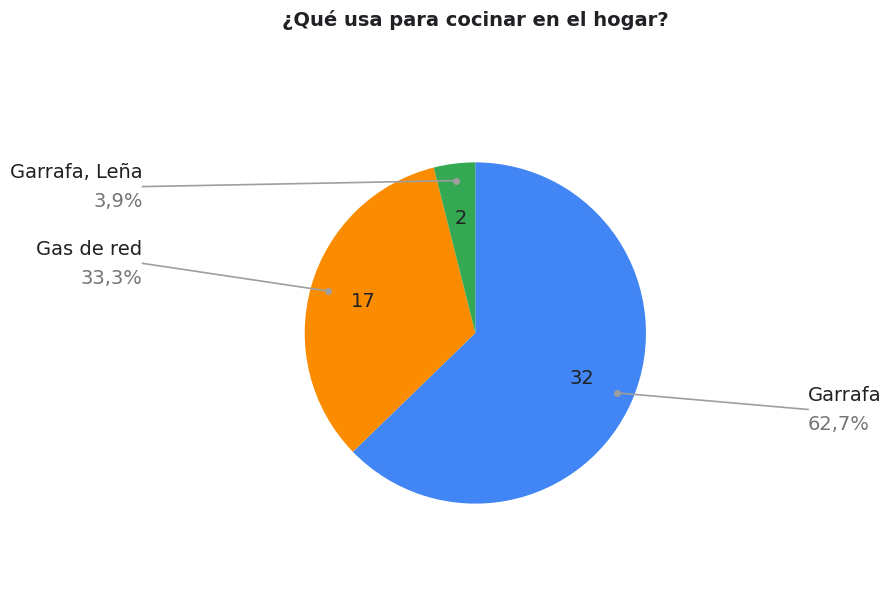

In [4]:
# Gráfico de torta: Qué usa para cocinar (3 categorías, línea sin subrayar)
graficar_torta(
    categorias=df_1_4_estandarizado['Elemento'],
    valores=df_1_4_estandarizado['fi'],
    titulo="¿Qué usa para cocinar en el hogar?",
    distancia_etiquetas_y=0.45
)


## 5. Pregunta 1.5: Equipamiento para cocinar en el hogar
Al tener **más de 5 categorías** (7 categorías), se grafica con un **gráfico de barras horizontales** que utiliza exactamente la misma paleta y orden de colores que el gráfico de torta (1. Azul, 2. Naranja, 3. Verde, 4. Amarillo, 5. Violeta, 6. Beige), con la regla de porcentajes menores a 2%.


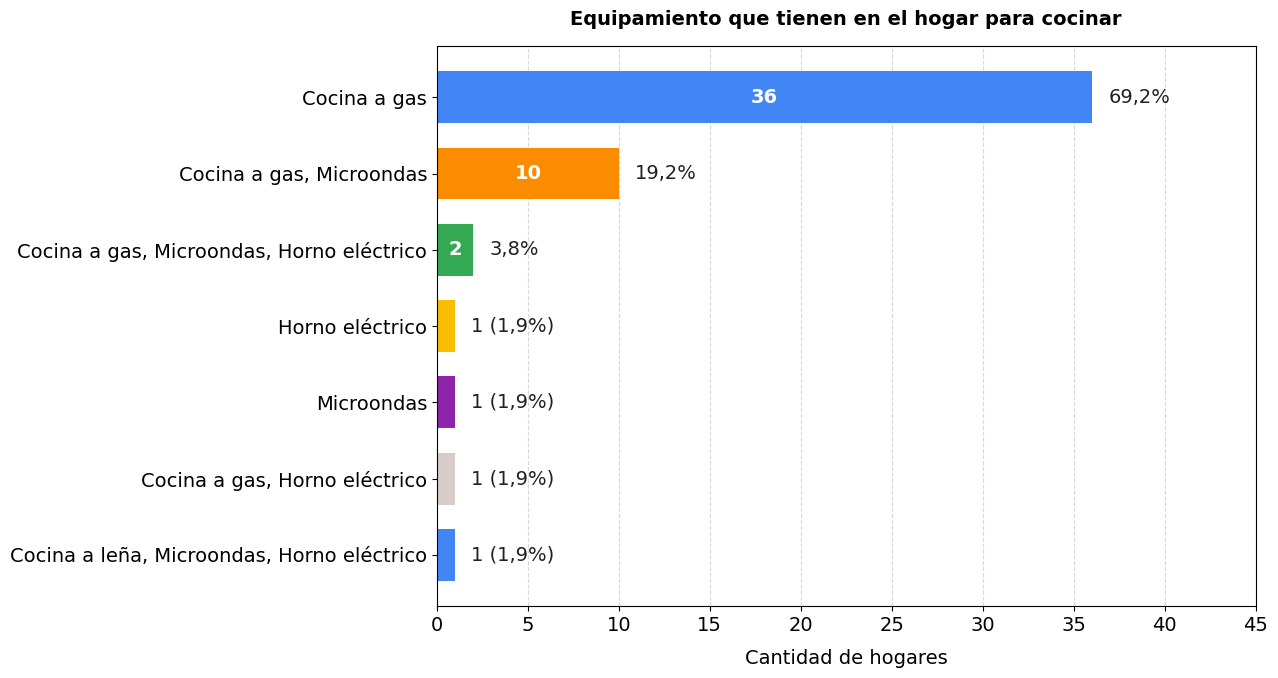

In [5]:
# Gráfico de barras horizontales con colores de torta (> 5 categorías)
graficar_barras_horizontales(
    etiquetas=df_1_5_estandarizado['Elemento'],
    valores=df_1_5_estandarizado['fi'],
    titulo="Equipamiento que tienen en el hogar para cocinar",
    xlabel="Cantidad de hogares",
    usar_colores_torta=True,         # Usa los mismos colores del gráfico de torta
    ordenar_mayor_a_menor=True,      # Ordena por frecuencia de mayor a menor
    figsize=(13, 7)
)


## 6. Pregunta 1.6: Comidas preparadas en el hogar


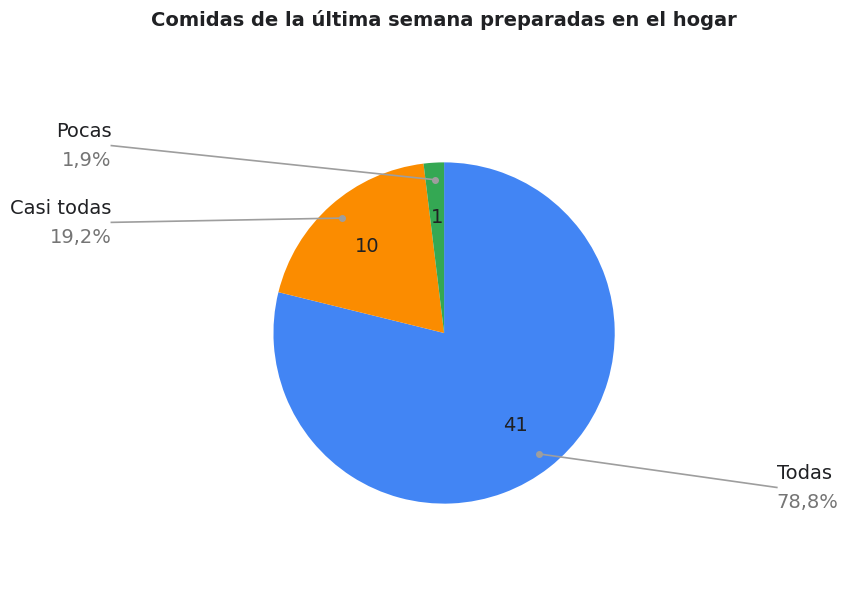

In [6]:
# Gráfico de torta: Proporción de comidas preparadas en el hogar (Línea sin subrayar)
graficar_torta(
    categorias=df_1_6_conteo.index,
    valores=df_1_6_conteo['fi'],
    titulo="Comidas de la última semana preparadas en el hogar",
    distancia_etiquetas_y=0.45
)


## 7. Pregunta 1.7: Agregado de sal durante la cocción


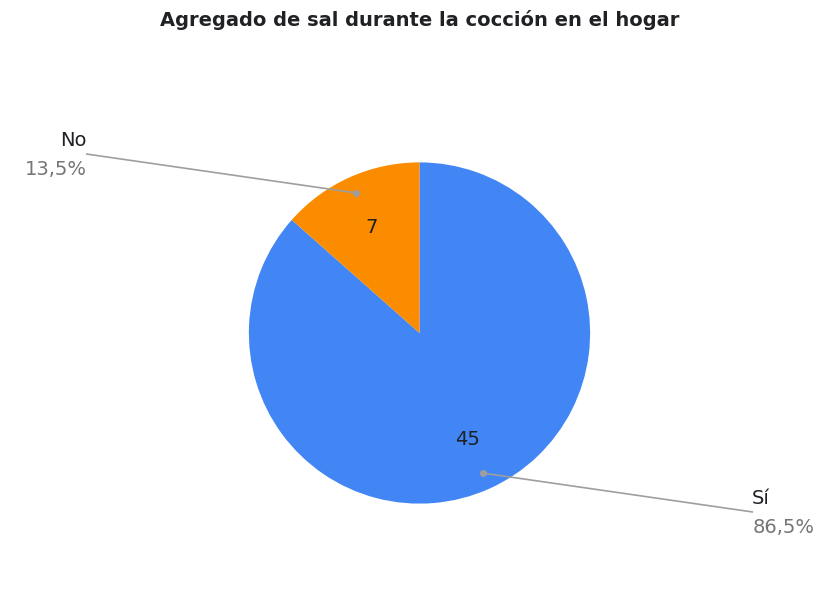

In [7]:
# Gráfico de torta: Pregunta binaria Sí / No (Positivo = Azul, Negativo = Naranja)
graficar_torta(
    categorias=df_1_7_conteo.index,
    valores=df_1_7_conteo['fi'],
    titulo="Agregado de sal durante la cocción en el hogar",
    es_binario=True
)
